# Sumativa 1. Características de navegación y compra
## Análisis descriptivo, estimación y pruebas de hipótesis

**Pregunta de investigación:** ¿Cómo difieren las características de navegación entre las sesiones con compra y sin compra?

**Objetivo general.** Comparar las características de navegación entre ambos grupos, considerando el tiempo dedicado a páginas de productos, la cantidad de páginas de productos y la cantidad de páginas administrativas visitadas.

**Objetivos específicos.**
1. Caracterizar la estructura, la calidad y la distribución de las variables del conjunto de datos.
2. Describir las tres variables seleccionadas por condición de compra y estimar sus medias mediante intervalos de confianza del 95%.
3. Contrastar la igualdad de medias del tiempo en productos y de la cantidad de páginas de productos entre los dos grupos.
4. Interpretar los resultados en el contexto de la navegación de un sitio de comercio electrónico, explicitando sus limitaciones.

El análisis utiliza **Online Shoppers Purchasing Intention**, publicado en UCI [1]. Una fila representa una **sesión de navegación**. El diseño es observacional: las diferencias entre los grupos permiten estudiar asociaciones, sin atribuir causalidad a las características de navegación. `Revenue` identifica si la sesión finalizó con una compra; no representa un monto monetario.

## 1. Datos, variables y diseño del análisis

El conjunto original contiene 12.330 sesiones y 18 variables. La fuente señala que las sesiones corresponden a usuarios distintos y fueron recopiladas durante un período de un año [1]. No se dispone de un diseño de muestreo probabilístico que permita representar a todas las tiendas. Las inferencias se interpretan, bajo los supuestos indicados más adelante, para sesiones comparables a las del sitio y período de origen.

| Variable seleccionada | Definición operacional | Tipo estadístico | Unidad de medida |
|---|---|---|---|
| `ProductRelated_Duration` | Tiempo total dedicado a páginas de productos; se divide por 60 para obtener `Tiempo_minutos` [2] | Cuantitativa continua | Minutos por sesión |
| `ProductRelated` | Cantidad de páginas de productos visitadas | Cuantitativa discreta | Páginas por sesión |
| `Administrative` | Cantidad de páginas relacionadas con la gestión de la cuenta visitadas [2] | Cuantitativa discreta | Páginas por sesión |
| `Revenue` | Registro de compra: `False` sin compra y `True` con compra | Categórica nominal binaria | Grupo de comparación |

Las páginas administrativas constituyen una categoría del dataset; el archivo no identifica pantallas concretas ni confirma que se haya completado un trámite. El tiempo en segundos y su conversión a minutos representan **la misma variable**.

Se desarrolla una exploración general del dataset y se profundiza en las tres variables seleccionadas. Se utilizan los casos disponibles para cada variable: el análisis de tiempo excluye únicamente sus valores faltantes; los conteos de páginas y las frecuencias categóricas mantienen todas las sesiones. La comparación inferencial comprende **dos contrastes bilaterales**. Las páginas administrativas se analizan mediante descriptiva e intervalos para sus medias, sin un tercer contraste.

### 1.1. Diccionario y clasificación estadística

La clasificación distingue el significado estadístico del tipo de almacenamiento: los códigos de navegador, región, sistema operativo y tráfico son etiquetas, aunque el CSV los almacene como enteros [1, 2, 4].

| Variable | Contenido | Tipo estadístico |
|---|---|---|
| Administrative | Páginas administrativas visitadas | Cuantitativa discreta |
| Administrative_Duration | Tiempo en páginas administrativas, segundos | Cuantitativa continua |
| Informational | Páginas informativas visitadas | Cuantitativa discreta |
| Informational_Duration | Tiempo en páginas informativas, segundos | Cuantitativa continua |
| ProductRelated | Páginas de productos visitadas | Cuantitativa discreta |
| ProductRelated_Duration | Tiempo en páginas de productos, segundos | Cuantitativa continua |
| BounceRates | Tasa de rebote asociada a las páginas visitadas | Cuantitativa continua |
| ExitRates | Tasa de salida asociada a las páginas visitadas | Cuantitativa continua |
| PageValues | Valor de las páginas visitadas según la métrica de origen | Cuantitativa continua |
| SpecialDay | Índice de proximidad a una fecha especial, entre 0 y 1 | Cuantitativa discreta |
| Month | Mes de la sesión, con orden de calendario cíclico | Categórica ordinal cíclica |
| OperatingSystems | Código de sistema operativo | Categórica nominal |
| Browser | Código de navegador | Categórica nominal |
| Region | Código de región | Categórica nominal |
| TrafficType | Código del origen del tráfico | Categórica nominal |
| VisitorType | Tipo de visitante | Categórica nominal |
| Weekend | Sesión durante fin de semana | Categórica nominal binaria |
| Revenue | Sesión finalizada con compra | Categórica nominal binaria |

`SpecialDay` es un índice con valores discretos; no se interpreta como una cantidad de días ni como una probabilidad. Las tasas se conservan en su escala original. No se calculan promedios ni correlaciones de los códigos nominales.

## 2. Reproducibilidad y carga de datos

El notebook utiliza rutas relativas a la carpeta `Sumativa_1` y el kernel **Python (Estadistica Computacional)**. Las dependencias están fijadas en `../requirements.txt`; la tabla siguiente registra las versiones de las cinco bibliotecas utilizadas en la ejecución.

**Entradas:**
- `datos_originales/online_shoppers_intention.csv`: copia original sin modificaciones.
- `datos_trabajo/online_shoppers_mcar.csv`: copia de trabajo con faltantes artificiales.
- `datos_trabajo/valores_ocultados.csv`: respaldo de las posiciones y duraciones ocultadas.

La copia de trabajo fue generada por `01_preparar_datos.ipynb` mediante selección aleatoria sin reemplazo del 10% de las duraciones, con semilla 42. Este notebook verifica y reutiliza esos archivos. El respaldo interviene únicamente en la comprobación de integridad y no se usa para rellenar los datos del análisis. Las tablas y figuras quedan incorporadas en las salidas del notebook.

Se emplean `pandas` para las tablas, `numpy` para los cálculos, `matplotlib` y `seaborn` para las figuras y `scipy.stats` para los intervalos y pruebas. La configuración gráfica mantiene unidades, colores de grupo y criterios de redondeo consistentes.

In [1]:
#Bibliotecas importadas
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

#Definiciones generales
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 3)
plt.rcParams.update({"font.size": 10, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

confianza = 0.95
alfa = 0.05
grupos = ["Sin compra", "Con compra"]
colores = {"Sin compra": "#35618D", "Con compra": "#C06A31"}

def numero(valor, decimales=2):
    # Presentación en español; los cálculos conservan la precisión original.
    return f"{valor:,.{decimales}f}".replace(",", "_").replace(".", ",").replace("_", ".")

versiones = pd.Series({"NumPy": np.__version__,
                      "pandas": pd.__version__, "SciPy": scipy.__version__,
                      "Matplotlib": matplotlib.__version__, "Seaborn": sns.__version__}, name="Versión")
display(versiones.to_frame())

,Versión
NumPy,2.5.3
pandas,2.3.3
SciPy,1.18.1
Matplotlib,3.11.2
Seaborn,0.13.2


### 2.1. Lectura y estructura

Se leen los tres CSV con `pandas.read_csv`, utilizando rutas relativas escritas como texto. Si falta una entrada, la lectura se detiene e informa el archivo que no se encontró. La opción `float_precision="round_trip"` preserva la precisión decimal de los archivos. `shape`, `head` e `info` permiten revisar dimensiones, primeras observaciones, columnas y tipos almacenados.

In [2]:
rutas = {
    "Original": "datos_originales/online_shoppers_intention.csv",
    "Trabajo": "datos_trabajo/online_shoppers_mcar.csv",
    "Respaldo": "datos_trabajo/valores_ocultados.csv"
}

df_original = pd.read_csv(rutas["Original"], float_precision="round_trip")
df = pd.read_csv(rutas["Trabajo"], float_precision="round_trip")
respaldo = pd.read_csv(rutas["Respaldo"], float_precision="round_trip")

print("Dimensiones del original:", df_original.shape)
print("Dimensiones de la copia de trabajo:", df.shape)
display(df.head())
df.info()

Dimensiones del original: (12330, 18)
Dimensiones de la copia de trabajo: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  11097 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

## 3. Calidad de los datos

### 3.1. Validación de Faltantes, duplicados e integridad entre base original y base de trabajo

Se construye un reporte por variable con el tipo almacenado, la cantidad de valores distintos y los faltantes del original y de la copia de trabajo. `isna().sum()` identifica ausencias y `duplicated().sum()` cuenta filas idénticas adicionales, considerando las 18 columnas de cada archivo.

In [3]:
calidad = pd.DataFrame({
    "Tipo almacenado": df.dtypes.astype(str),
    "Valores distintos": df.nunique(),
    "Faltantes original": df_original.isna().sum(),
    "Faltantes trabajo": df.isna().sum(),
    "Faltantes trabajo (%)": df.isna().mean() * 100
})
display(calidad.round(2))
duplicados_original = int(df_original.duplicated().sum())
duplicados_trabajo = int(df.duplicated().sum())
print("Filas idénticas adicionales en el original:", duplicados_original)
print("Filas idénticas adicionales en la copia de trabajo:", duplicados_trabajo)

,Tipo almacenado,Valores distintos,Faltantes original,Faltantes trabajo,Faltantes trabajo (%)
Administrative,int64,27,0,0,0.0
Administrative_Duration,float64,3335,0,0,0.0
Informational,int64,17,0,0,0.0
Informational_Duration,float64,1258,0,0,0.0
ProductRelated,int64,311,0,0,0.0
ProductRelated_Duration,float64,8677,0,1233,10.0
BounceRates,float64,1872,0,0,0.0
ExitRates,float64,4777,0,0,0.0
PageValues,float64,2704,0,0,0.0
SpecialDay,float64,6,0,0,0.0


Filas idénticas adicionales en el original: 125
Filas idénticas adicionales en la copia de trabajo: 115


La generación artificial de faltantes utiliza un mecanismo **MCAR** (*Missing Completely At Random*): las posiciones se seleccionaron sin usar el valor del tiempo, la compra u otra variable. Este procedimiento conserva una versión fija para el análisis y los valores originales para futuras evaluaciones de imputación [3].

La comprobación siguiente reproduce las posiciones esperadas con la semilla 42, verifica el respaldo y reconstruye temporalmente el original en una tabla de validación. Esta tabla no interviene en los cálculos estadísticos. La igualdad entre las tablas confirma que la copia conserva los valores originales fuera de las posiciones ocultadas.

In [4]:
columna_tiempo = "ProductRelated_Duration"
assert df_original.shape == df.shape == (12330, 18)
assert df_original.columns.equals(df.columns)
assert df_original.isna().sum().sum() == 0

cantidad_ocultada = int(len(df_original) * 0.10)
generador = np.random.default_rng(42)
posiciones_esperadas = np.sort(generador.choice(
    len(df_original), size=cantidad_ocultada, replace=False
))
posiciones_faltantes = np.flatnonzero(df[columna_tiempo].isna())
assert np.array_equal(posiciones_faltantes, posiciones_esperadas)
assert np.array_equal(respaldo["fila_original"], posiciones_esperadas)
assert np.array_equal(respaldo["valor_original"],
                      df_original.loc[posiciones_esperadas, columna_tiempo])

validacion = df.copy()
validacion.loc[posiciones_esperadas, columna_tiempo] = respaldo["valor_original"].to_numpy()
assert validacion.equals(df_original)
del validacion

print("Integridad verificada. Valores ocultados:", cantidad_ocultada)
print("Otras variables modificadas: 0")

Integridad verificada. Valores ocultados: 1233
Otras variables modificadas: 0


### 3.2. Validación de Rangos y consistencia

Los conteos deben ser enteros no negativos; las duraciones y `PageValues` no deben ser negativos; las tasas e índices deben estar entre 0 y 1. Se revisan valores no finitos, las categorías de mes, visitante y variables binarias, y la consistencia entre conteos y tiempos. Estas comprobaciones delimitan errores detectables con el archivo disponible; no certifican el proceso de medición de origen.

In [5]:
numericas = ["Administrative", "Administrative_Duration", "Informational",
             "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
             "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
conteos = ["Administrative", "Informational", "ProductRelated"]
duraciones = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
meses = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

rangos = df[numericas].agg(["min", "max"]).T.rename(columns={"min": "Mínimo", "max": "Máximo"})
rangos["Ceros"] = df[numericas].eq(0).sum()
rangos["Negativos"] = df[numericas].lt(0).sum()
rangos["Infinitos"] = np.isinf(df[numericas]).sum()
display(rangos)

controles = {
    "Conteos enteros no negativos": all(
        ((df[v].dropna() >= 0) & (df[v].dropna() % 1 == 0)).all() for v in conteos),
    "Duraciones y valor de página no negativos":
        all(df[v].dropna().ge(0).all() for v in duraciones + ["PageValues"]),
    "Tasas e índice entre 0 y 1": all(df[v].dropna().between(0, 1).all()
        for v in ["BounceRates", "ExitRates", "SpecialDay"]),
    "Ausencia de valores infinitos": not np.isinf(df[numericas]).any().any(),
    "Meses válidos": df["Month"].isin(meses).all(),
    "Tipos de visitante válidos": df["VisitorType"].isin(
        ["Returning_Visitor", "New_Visitor", "Other"]).all(),
    "Compra y fin de semana binarios": all(df[v].isin([False, True]).all()
        for v in ["Revenue", "Weekend"])
}
display(pd.Series(controles, name="Cumple").to_frame())
assert all(controles.values()), "Se detectaron valores fuera de los dominios definidos."

consistencia = []
for cantidad, duracion in zip(conteos, duraciones):
    consistencia.append({"Tipo de página": cantidad,
        "Conteo 0 y duración positiva": int(((df_original[cantidad] == 0) &
                                             (df_original[duracion] > 0)).sum()),
        "Conteo positivo y duración 0": int(((df_original[cantidad] > 0) &
                                             (df_original[duracion] == 0)).sum())})
display(pd.DataFrame(consistencia).set_index("Tipo de página"))

,Mínimo,Máximo,Ceros,Negativos,Infinitos
Administrative,0.0,27.000,5768,0,0
Administrative_Duration,0.0,3398.750,5903,0,0
Informational,0.0,24.000,9699,0,0
Informational_Duration,0.0,2549.375,9925,0,0
ProductRelated,0.0,705.000,38,0,0
ProductRelated_Duration,0.0,63973.522,676,0,0
BounceRates,0.0,0.200,5518,0,0
ExitRates,0.0,0.200,76,0,0
PageValues,0.0,361.764,9600,0,0
SpecialDay,0.0,1.000,11079,0,0


,Cumple
Conteos enteros no negativos,True
Duraciones y valor de página no negativos,True
Tasas e índice entre 0 y 1,True
Ausencia de valores infinitos,True
Meses válidos,True
Tipos de visitante válidos,True
Compra y fin de semana binarios,True


,Conteo 0 y duración positiva,Conteo positivo y duración 0
Tipo de página,,
Administrative,0,135
Informational,0,226
ProductRelated,0,717


**Resultado de la revisión de calidad.** El original no tiene faltantes y la copia de trabajo contiene 1.233 ausencias, exclusivamente en la duración de productos. Los datos cumplen las reglas de validación establecidas, como la ausencia de valores negativos en las cantidades y duraciones, y la presencia de categorías válidas.
Además, no se encontraron sesiones con tiempo de navegación positivo cuando la cantidad de páginas visitadas era cero. Sin embargo, existen sesiones con páginas visitadas y duración registrada igual a cero. Como no se conoce la causa de estos registros, se decidió conservarlos para el análisis.

Se conservan las **125 filas idénticas adicionales del original**: la coincidencia de sus atributos no basta para identificar sesiones duplicadas, ya que no existe un identificador de sesión en el archivo. El conteo de filas idénticas es 115 en la copia de trabajo porque la ubicación de los faltantes cambia algunas coincidencias; **no se eliminaron filas**. Los valores extremos se evalúan posteriormente mediante el rango intercuartílico.

La ausencia MCAR permite utilizar los tiempos observados bajo ese mecanismo, con pérdida de precisión respecto de los datos completos. Ocultar valores al azar no convierte al dataset original en una muestra representativa de otras tiendas. Se conserva la copia de trabajo sin imputación y se informa el tamaño disponible en cada análisis.

## 4. Preparación de los datos para el análisis

En esta etapa se ajustaron los tipos de datos para mejorar el uso de memoria. Las variables categóricas se clasificaron según sus características y las variables enteras se convirtieron a tipos que requieren menos espacio. Se mantuvo la precisión de las variables de duración y se comprobó que estas modificaciones no alteraran los valores originales[4]. Además, se incorporó `Tiempo_minutos` que expresa el tiempo de navegación en minutos para facilitar su interpretación y se identificaron las sesiones según si terminaron o no en una compra. Finalmente, se conservaron los registros con datos faltantes, ya que estos se considerarán según las necesidades de cada análisis, evitando eliminar información innecesariamente.

In [6]:
valores_antes = df.copy()
memoria_antes = df.memory_usage(deep=True).sum()
df["Month"] = pd.Categorical(df["Month"], categories=meses, ordered=True)
for columna in ["OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]:
    df[columna] = df[columna].astype("category")
for columna in conteos:
    df[columna] = pd.to_numeric(df[columna], downcast="integer")
for columna in df.columns:
    assert valores_antes[columna].astype("object").equals(df[columna].astype("object"))
memoria_despues = df.memory_usage(deep=True).sum()
del valores_antes

display(pd.DataFrame({"Memoria inicial (KiB)": [memoria_antes / 1024],
                      "Memoria final (KiB)": [memoria_despues / 1024],
                      "Reducción (%)": [100 * (1 - memoria_despues / memoria_antes)]}).round(2))

df["Tiempo_minutos"] = df["ProductRelated_Duration"] / 60
df["Grupo"] = pd.Categorical(df["Revenue"].map({False: "Sin compra", True: "Con compra"}),
                              categories=grupos, ordered=True)
seleccionadas = ["Tiempo_minutos", "ProductRelated", "Administrative"]
nombres = {"Tiempo_minutos": "Tiempo en productos", "ProductRelated": "Páginas de productos",
           "Administrative": "Páginas administrativas"}
unidades = {"Tiempo_minutos": "minutos", "ProductRelated": "páginas", "Administrative": "páginas"}

muestras = df.groupby("Grupo", observed=True).agg(
    Sesiones=("Revenue", "size"),
    Tiempo_disponible=("Tiempo_minutos", "count"),
    Paginas_productos_disponibles=("ProductRelated", "count"),
    Paginas_administrativas_disponibles=("Administrative", "count")
)
muestras["Tiempo faltante"] = muestras["Sesiones"] - muestras["Tiempo_disponible"]
muestras["Tiempo faltante (%)"] = muestras["Tiempo faltante"] / muestras["Sesiones"] * 100
display(muestras.round(2))

,Memoria inicial (KiB),Memoria final (KiB),Reducción (%)
0,2783.0,822.17,70.46


,Sesiones,Tiempo_disponible,Paginas_productos_disponibles,Paginas_administrativas_disponibles,Tiempo faltante,Tiempo faltante (%)
Grupo,,,,,,
Sin compra,10422,9387,10422,10422,1035,9.93
Con compra,1908,1710,1908,1908,198,10.38


Se realizó una optimización de los tipos de datos del conjunto original, compuesto por 12.330 registros y 18 variables.
El consumo de memoria disminuyó de 2.783,00 KB a 822,17 KB, lo que representa una reducción del **70,46%**.

La muestra contiene 10.422 sesiones sin compra y 1.908 con compra. Para la duración se dispone de 9.387 y 1.710 observaciones, respectivamente: 11.097 en total. Para ambas cantidades de páginas se mantienen las 12.330 sesiones. Las proporciones de faltantes dentro de cada grupo pueden diferir del 10% porque la selección aleatoria se realizó sobre el conjunto completo, sin estratificar por compra.

## 5. Análisis exploratorio de datos
### 5.1. Variables categóricas: frecuencias absolutas y relativas

Se contabilizan las ocho variables categóricas mediante `value_counts` y se divide cada frecuencia por el total de sesiones para obtener porcentajes. Para `Month` se respeta el calendario; enero y abril se muestran con frecuencia cero porque no aparecen en el archivo. Las barras representan porcentajes del conjunto completo y parten de cero. No se asignan nombres de navegadores, regiones o sistemas operativos a códigos cuyo significado específico no está documentado.

Revenue


,Frecuencia absoluta,Frecuencia relativa (%)
Revenue,,
False,10422,84.53
True,1908,15.47


VisitorType


,Frecuencia absoluta,Frecuencia relativa (%)
VisitorType,,
New_Visitor,1694,13.74
Other,85,0.69
Returning_Visitor,10551,85.57


Weekend


...

,Frecuencia absoluta,Frecuencia relativa (%)
Browser,,
1,2462,19.97
2,7961,64.57
3,105,0.85
4,736,5.97
5,467,3.79
6,174,1.41
7,49,0.40
8,135,1.09
9,1,0.01


Region


,Frecuencia absoluta,Frecuencia relativa (%)
Region,,
1,4780,38.77
2,1136,9.21
3,2403,19.49
4,1182,9.59
5,318,2.58
6,805,6.53
7,761,6.17
8,434,3.52
9,511,4.14


TrafficType


,Frecuencia absoluta,Frecuencia relativa (%)
TrafficType,,
1,2451,19.88
2,3913,31.74
3,2052,16.64
4,1069,8.67
5,260,2.11
6,444,3.60
7,40,0.32
8,343,2.78
9,42,0.34


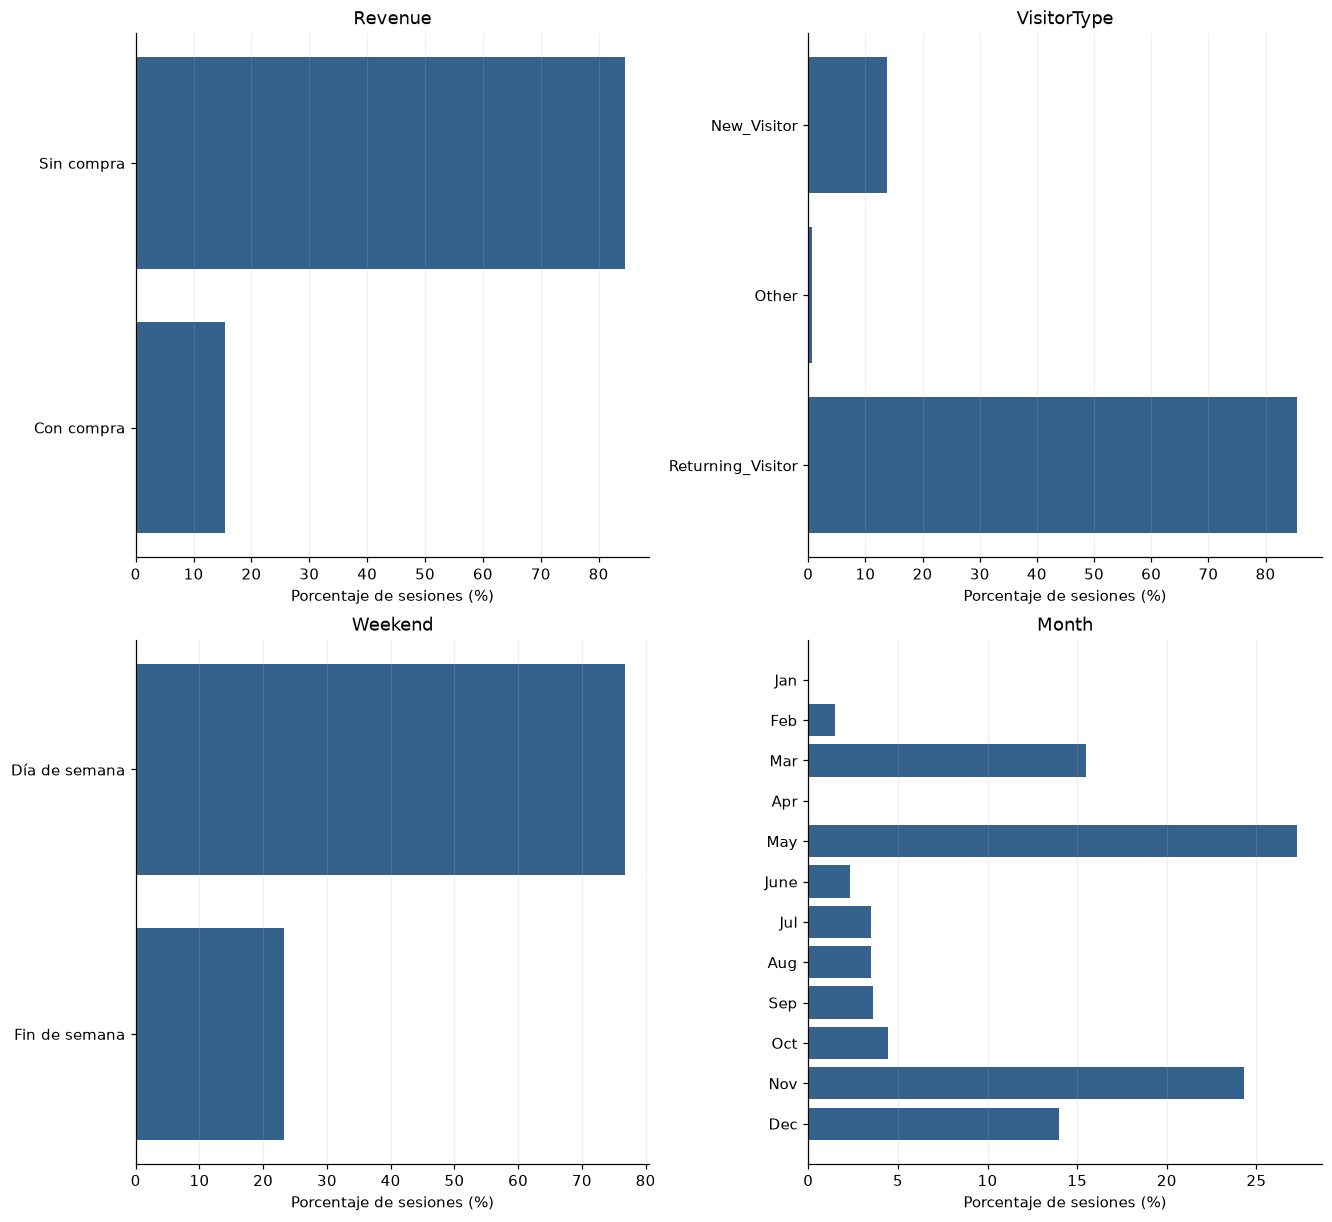

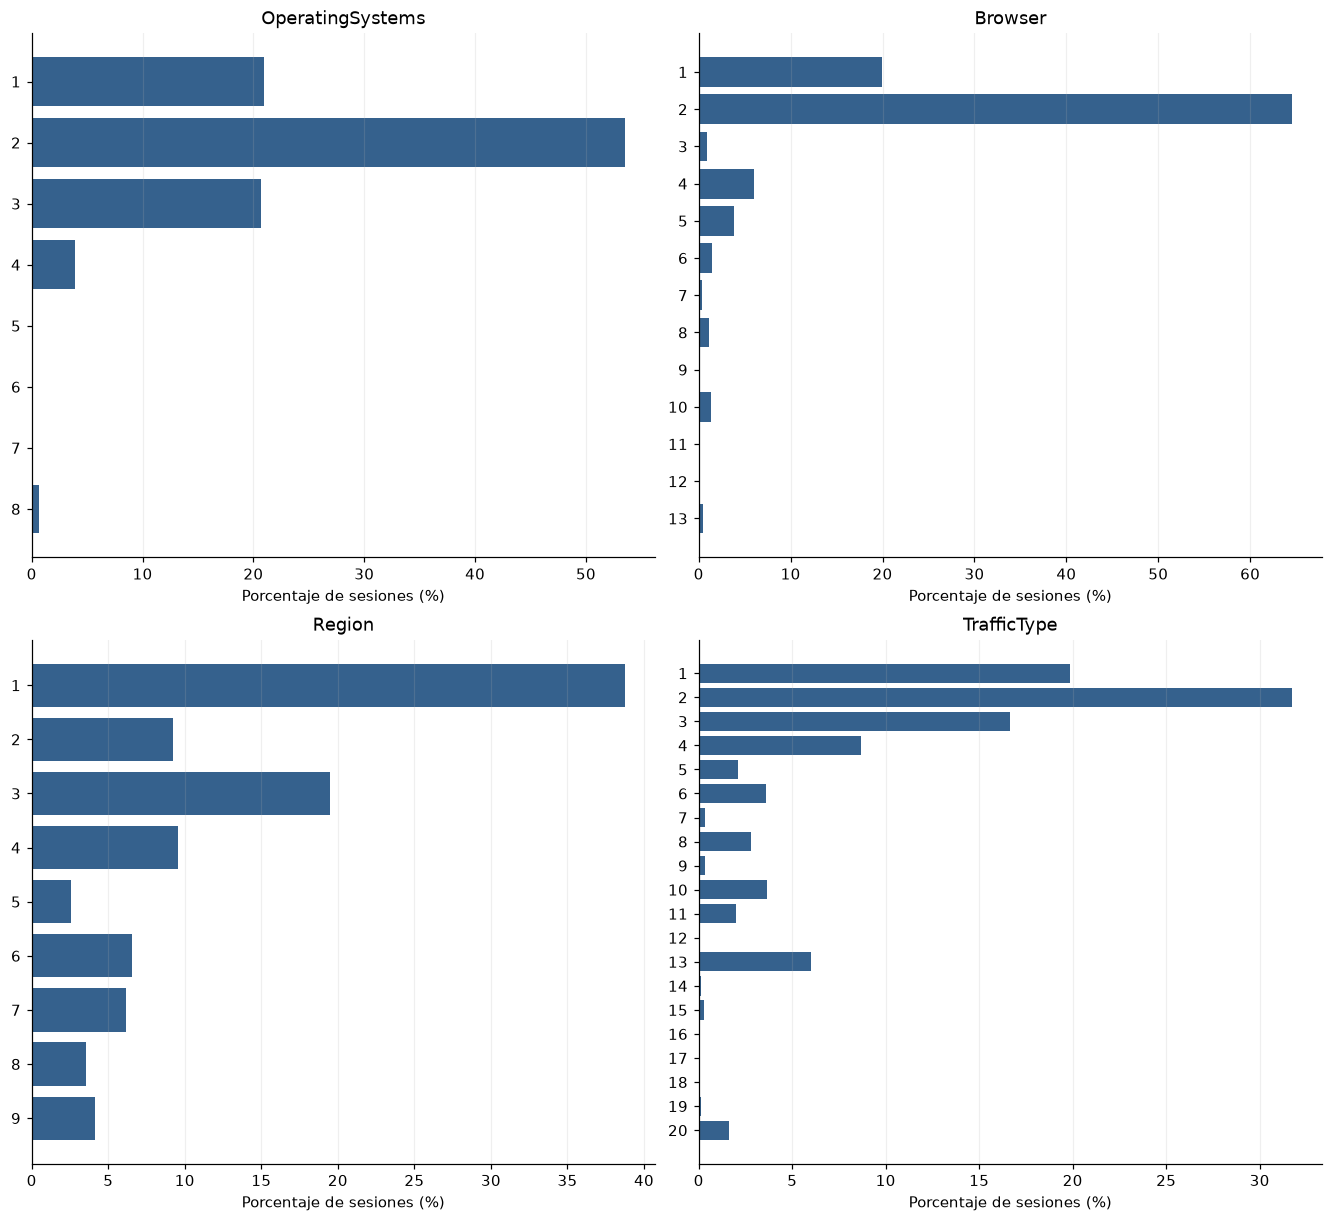

In [7]:
categoricas = ["Revenue", "VisitorType", "Weekend", "Month",
               "OperatingSystems", "Browser", "Region", "TrafficType"]
frecuencias = {}
for columna in categoricas:
    serie = df[columna].value_counts(dropna=False, sort=False)
    serie = serie.reindex(meses, fill_value=0) if columna == "Month" else serie.sort_index()
    tabla = pd.DataFrame({"Frecuencia absoluta": serie,
                          "Frecuencia relativa (%)": serie / len(df) * 100})
    tabla.index.name = columna
    frecuencias[columna] = tabla
    print(columna)
    display(tabla.round(2))

for bloque, columnas in enumerate([categoricas[:4], categoricas[4:]], start=1):
    fig, ejes = plt.subplots(2, 2, figsize=(12, 11), layout="constrained")
    for eje, columna in zip(ejes.flat, columnas):
        tabla = frecuencias[columna]
        etiquetas = tabla.index.astype(str).tolist()
        if columna == "Revenue":
            etiquetas = ["Sin compra" if x == "False" else "Con compra" for x in etiquetas]
        elif columna == "Weekend":
            etiquetas = ["Día de semana" if x == "False" else "Fin de semana" for x in etiquetas]
        eje.barh(etiquetas, tabla["Frecuencia relativa (%)"], color="#35618D")
        eje.invert_yaxis()
        eje.set(title=columna, xlabel="Porcentaje de sesiones (%)")
        eje.grid(axis="x", alpha=0.2)
    plt.show()

**Interpretación.** Las sesiones con compra representan el **15,47%** del total y las de visitantes recurrentes el **85,57%**. El **23,26%** corresponde a fines de semana. Mayo y noviembre concentran el **51,60%** de los registros. Predominan los códigos 2 de sistema operativo, 2 de navegador, 1 de región y 2 de tráfico. Estas frecuencias caracterizan la composición del archivo; no identifican por sí solas una mayor propensión de compra de cada categoría. El desequilibrio entre los grupos exige comparar medidas por sesión y distribuciones normalizadas, en lugar de interpretar cantidades absolutas de sesiones como diferencias de comportamiento.

### 5.2. Caracterización de las variables numéricas

El resumen general utiliza `describe` para obtener cantidad de observaciones, media, desviación estándar muestral, extremos y cuartiles de las diez variables numéricas originales. Las duraciones de esta tabla conservan la unidad de segundos. Los histogramas muestran la forma de cada distribución en su rango completo [5, 6, 7]. Las tres variables del problema se presentan después con mayor detalle, utilizando minutos para el tiempo en productos.

,n,Media,Desv. estándar,Mínimo,Q1,Mediana,Q3,Máximo
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,11097.0,1192.925,1924.578,0.0,183.833,597.633,1459.577,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


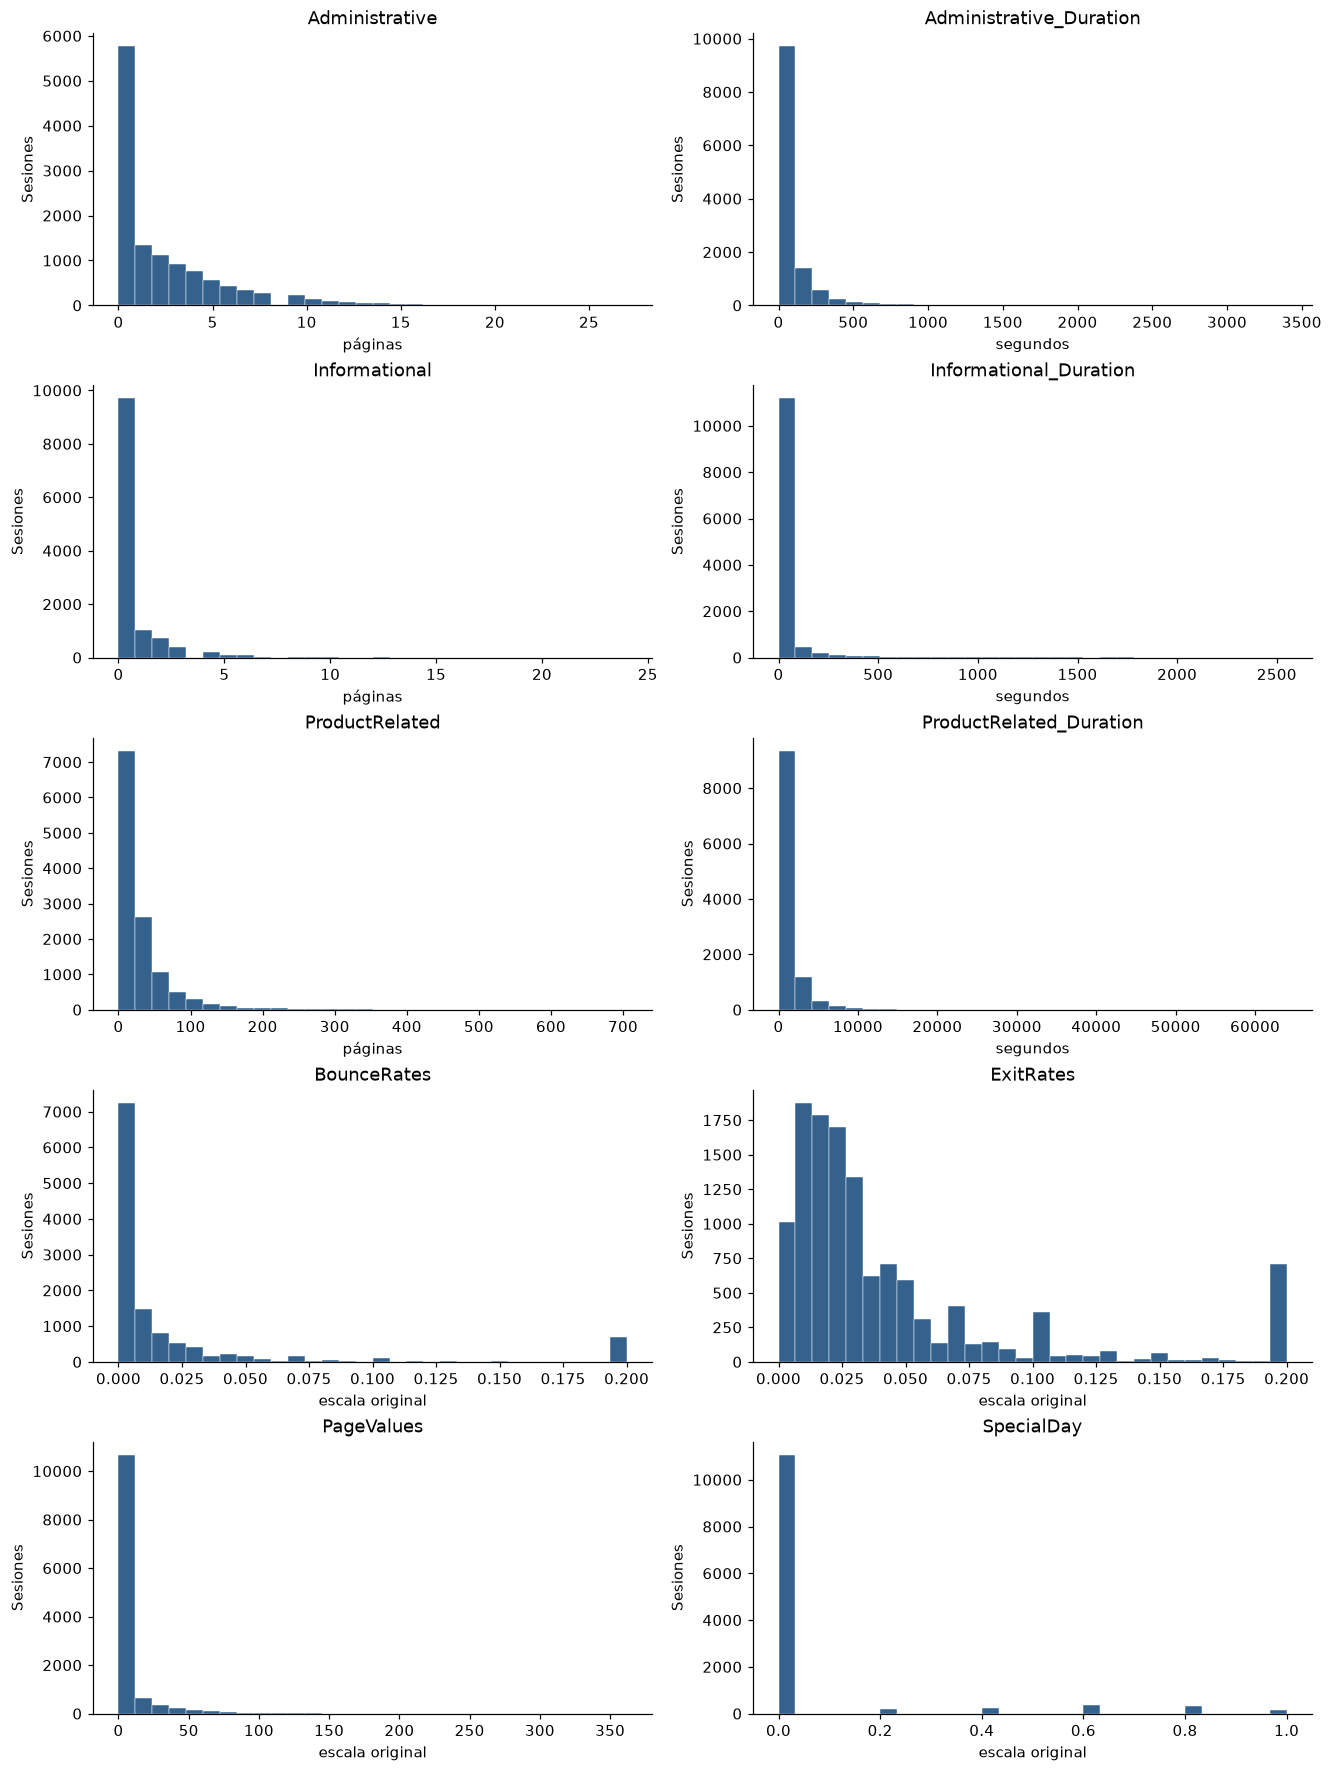

In [8]:
resumen_general = df[numericas].describe().T.rename(columns={
    "count": "n", "mean": "Media", "std": "Desv. estándar", "min": "Mínimo",
    "25%": "Q1", "50%": "Mediana", "75%": "Q3", "max": "Máximo"
})
display(resumen_general.round(3))

fig, ejes = plt.subplots(5, 2, figsize=(12, 16), layout="constrained")
for eje, columna in zip(ejes.flat, numericas):
    valores = df[columna].dropna()
    eje.hist(valores, bins=30, color="#35618D", edgecolor="white", linewidth=0.3)
    unidad = "segundos" if columna in duraciones else (
        "páginas" if columna in conteos else "escala original")
    eje.set(title=columna, xlabel=unidad, ylabel="Sesiones")
plt.show()

**Interpretación del panorama general.** Los conteos, las duraciones y el valor de página presentan concentración en valores bajos y colas hacia la derecha. Las tasas de rebote y salida se concentran cerca de cero y contienen valores más altos menos frecuentes. `SpecialDay` acumula registros en cero y en algunos niveles discretos: un histograma de ese índice no se interpreta como una distribución continua de días. La diferencia entre las escalas exige mantener las unidades en las tablas y figuras y evita comparar directamente magnitudes como segundos y tasas.

### 5.3. Tendencia central, dispersión y forma por condición de compra

Para cada variable seleccionada y grupo se calculan media, mediana y moda; desviación estándar y varianza muestrales con `ddof=1`; rango, cuartiles y rango intercuartílico (IQR); coeficiente de variación (CV), asimetría y curtosis de exceso. El IQR es $Q_3-Q_1$ y el CV es $100s/|\bar{x}|$. El CV se informa solo cuando la media es distinta de cero. En estas variables existe un cero con significado, aunque una media pequeña puede hacer grande el CV [5, 6].

La varianza se expresa en unidades al cuadrado; la desviación estándar, el rango y el IQR conservan la unidad de la variable. Una media de páginas puede tener decimales, aun cuando cada sesión registre un conteo entero. La moda conserva todos los valores empatados y su interpretación en tiempos depende de la precisión del registro.

In [9]:
registros = []
for variable in seleccionadas:
    for grupo in grupos:
        valores = df.loc[df["Grupo"] == grupo, variable].dropna()
        q1, q3 = valores.quantile([0.25, 0.75])
        media, desviacion = valores.mean(), valores.std(ddof=1)
        registros.append({
            "Variable": nombres[variable], "Grupo": grupo, "Unidad": unidades[variable],
            "n": len(valores), "Media": media, "Mediana": valores.median(),
            "Moda": ", ".join(numero(x, 0 if variable != "Tiempo_minutos" else 2)
                               for x in valores.mode()),
            "Desv. estándar": desviacion, "Varianza": valores.var(ddof=1),
            "Mínimo": valores.min(), "Máximo": valores.max(), "Q1": q1, "Q3": q3,
            "Rango": valores.max() - valores.min(), "IQR": q3 - q1,
            "CV (%)": 100 * desviacion / abs(media) if media != 0 else np.nan,
            "Asimetría": valores.skew(), "Curtosis de exceso": valores.kurt(),
            "Ceros (%)": valores.eq(0).mean() * 100
        })
descriptivos = pd.DataFrame(registros).set_index(["Variable", "Grupo"])
display(descriptivos[["Unidad", "n", "Media", "Mediana", "Moda", "Desv. estándar", "Varianza"]].round(3))
display(descriptivos[["Mínimo", "Máximo", "Q1", "Q3", "Rango", "IQR", "CV (%)"]].round(3))
display(descriptivos[["Asimetría", "Curtosis de exceso", "Ceros (%)"]].round(3))

Unidad      n   Media  Mediana  Moda  \
Variable                Grupo                                               
Tiempo en productos     Sin compra  minutos   9387  17.858    8.456  0,00   
                        Con compra  minutos   1710  30.991   18.301  0,00   
Páginas de productos    Sin compra  páginas  10422  28.715   16.000     1   
                        Con compra  páginas   1908  48.210   29.000    10   
Páginas administrativas Sin compra  páginas  10422   2.118    0.000     0   
                        Con compra  páginas   1908   3.394    2.000     0   

                                    Desv. estándar  Varianza  
Variable                Grupo                                 
Tiempo en productos     Sin compra          30.522   931.607  
                        Con compra          37.654  1417.790  
Páginas de productos    Sin compra          40.745  1660.132  
                        Con compra          58.267  3395.086  
Páginas administrativas Sin compra           3.202    10.256  
                        Con compra           3.731    13.917

Mínimo    Máximo      Q1      Q3  \
Variable                Grupo                                          
Tiempo en productos     Sin compra     0.0  1066.225   2.503  22.073   
                        Con compra     0.0   450.164   9.026  37.676   
Páginas de productos    Sin compra     0.0   705.000   6.000  35.000   
                        Con compra     0.0   534.000  15.000  57.000   
Páginas administrativas Sin compra     0.0    27.000   0.000   3.000   
                        Con compra     0.0    26.000   0.000   5.000   

                                       Rango     IQR   CV (%)  
Variable                Grupo                                  
Tiempo en productos     Sin compra  1066.225  19.569  170.913  
                        Con compra   450.164  28.650  121.497  
Páginas de productos    Sin compra   705.000  29.000  141.895  
                        Con compra   534.000  42.000  120.861  
Páginas administrativas Sin compra    27.000   3.000  151.222  
                        Con compra    26.000   5.000  109.928

Asimetría  Curtosis de exceso  Ceros (%)
Variable                Grupo                                               
Tiempo en productos     Sin compra      9.151             205.029      7.095
                        Con compra      3.293              18.046      0.585
Páginas de productos    Sin compra      4.694              38.839      0.307
                        Con compra      3.259              15.065      0.314
Páginas administrativas Sin compra      2.095               5.484     50.413
                        Con compra      1.455               2.411     26.939

**Tiempo en productos.** Para sesiones sin compra, la media es **17,86** y la mediana **8,46** minutos; sesiones con compra son **30,99** y **18,30**, respectivamente. Las desviaciones estándar son 30,52 y 37,65; los IQR son 19,57 y 28,65 minutos. Los ceros representan 7,09% y 0,58% de cada grupo.

**Páginas de productos.** Para sesiones sin compra, la media es **28,71** y la mediana **16,00** páginas; sesiones con compra son **48,21** y **29,00**, respectivamente. Las desviaciones estándar son 40,74 y 58,27; los IQR son 29,00 y 42,00 páginas. Los ceros representan 0,31% y 0,31% de cada grupo.

**Páginas administrativas.** Para sesiones sin compra, la media es **2,12** y la mediana **0,00** páginas; con compra son **3,39** y **2,00**, respectivamente. Las desviaciones estándar son 3,20 y 3,73; los IQR son 3,00 y 5,00 páginas. Los ceros representan 50,41% y 26,94% de cada grupo.

Las medias superan a las medianas en los seis casos y los coeficientes de asimetría son positivos. Las colas derechas y los valores extremos elevan las medias. La curtosis de exceso es especialmente alta en el tiempo de sesiones sin compra, por lo que el promedio debe leerse junto con la mediana y el IQR. La variabilidad dentro de cada grupo impide identificar el resultado de una sesión únicamente a partir de su duración o de un conteo de páginas.

### 5.4. Identificación de valores atípicos

Se aplica por variable y grupo la regla de Tukey: valores menores que $Q_1-1{,}5\,IQR$ o mayores que $Q_3+1{,}5\,IQR$ se señalan como atípicos [6, 8]. Los límites se calculan dentro de cada grupo para describir sus distribuciones. Esta regla identifica observaciones alejadas del centro, no errores demostrados. Se cuantifican los casos y se inspeccionan los tiempos más altos junto con sus conteos de páginas.

In [10]:
registros_atipicos = []
for variable in seleccionadas:
    for grupo in grupos:
        valores = df.loc[df["Grupo"] == grupo, variable].dropna()
        q1, q3 = valores.quantile([0.25, 0.75])
        IQR = q3 - q1
        inferior, superior = q1 - 1.5 * IQR, q3 + 1.5 * IQR
        cantidad = ((valores < inferior) | (valores > superior)).sum()
        registros_atipicos.append({"Variable": nombres[variable], "Grupo": grupo,
            "Límite inferior": inferior, "Límite superior": superior,
            "Atípicos": int(cantidad), "Atípicos (%)": cantidad / len(valores) * 100})
atipicos = pd.DataFrame(registros_atipicos).set_index(["Variable", "Grupo"])
display(atipicos.round(3))
display(df.nlargest(5, "Tiempo_minutos")[
    ["Tiempo_minutos", "ProductRelated", "Administrative", "Grupo"]
].rename_axis("Posición en el archivo (desde 0)").round(3))

Límite inferior  Límite superior  \
Variable                Grupo                                          
Tiempo en productos     Sin compra          -26.851           51.427   
                        Con compra          -33.949           80.651   
Páginas de productos    Sin compra          -37.500           78.500   
                        Con compra          -48.000          120.000   
Páginas administrativas Sin compra           -4.500            7.500   
                        Con compra           -7.500           12.500   

                                    Atípicos  Atípicos (%)  
Variable                Grupo                               
Tiempo en productos     Sin compra       718         7.649  
                        Con compra       150         8.772  
Páginas de productos    Sin compra       813         7.801  
                        Con compra       166         8.700  
Páginas administrativas Sin compra       793         7.609  
                        Con compra        58         3.040

,Tiempo_minutos,ProductRelated,Administrative,Grupo
Posición en el archivo (desde 0),,,,
8071,1066.225,449,5,Sin compra
5152,719.521,705,17,Sin compra
9238,499.508,343,15,Sin compra
8784,450.164,517,20,Con compra
8308,414.069,584,27,Sin compra


**Decisión sobre atípicos.** Se conservan todas las observaciones disponibles. El mayor tiempo registrado supera los mil minutos y merece cautela, pero no se dispone de trazas de eventos para determinar si corresponde a un error o a una característica de la medición. La eliminación automática cambiaría el parámetro estudiado y podría ocultar parte de la variabilidad. La mediana, el IQR, la inspección gráfica y las limitaciones de la inferencia acompañan a los resultados basados en medias.

### 5.5. Visualización y comparación de las variables

Se elaboraron histogramas y diagramas de caja para comparar el comportamiento de navegación entre las sesiones con compra y sin compra.
Los histogramas permiten observar la forma general de la distribución de cada variable. Para facilitar la comparación entre grupos de distinto tamaño, se utiliza densidad en lugar de frecuencia absoluta.
Además, se presentan dos versiones de los diagramas de caja: una que mantiene visibles los valores atípicos y otra que los oculta solo con fines de visualización. Esto permite, por una parte, identificar la presencia de valores extremos y, por otra, apreciar con mayor claridad la mediana y la dispersión central de los datos.
En todos los casos, los valores atípicos permanecen en el conjunto de datos y no se excluyen de los cálculos estadísticos.

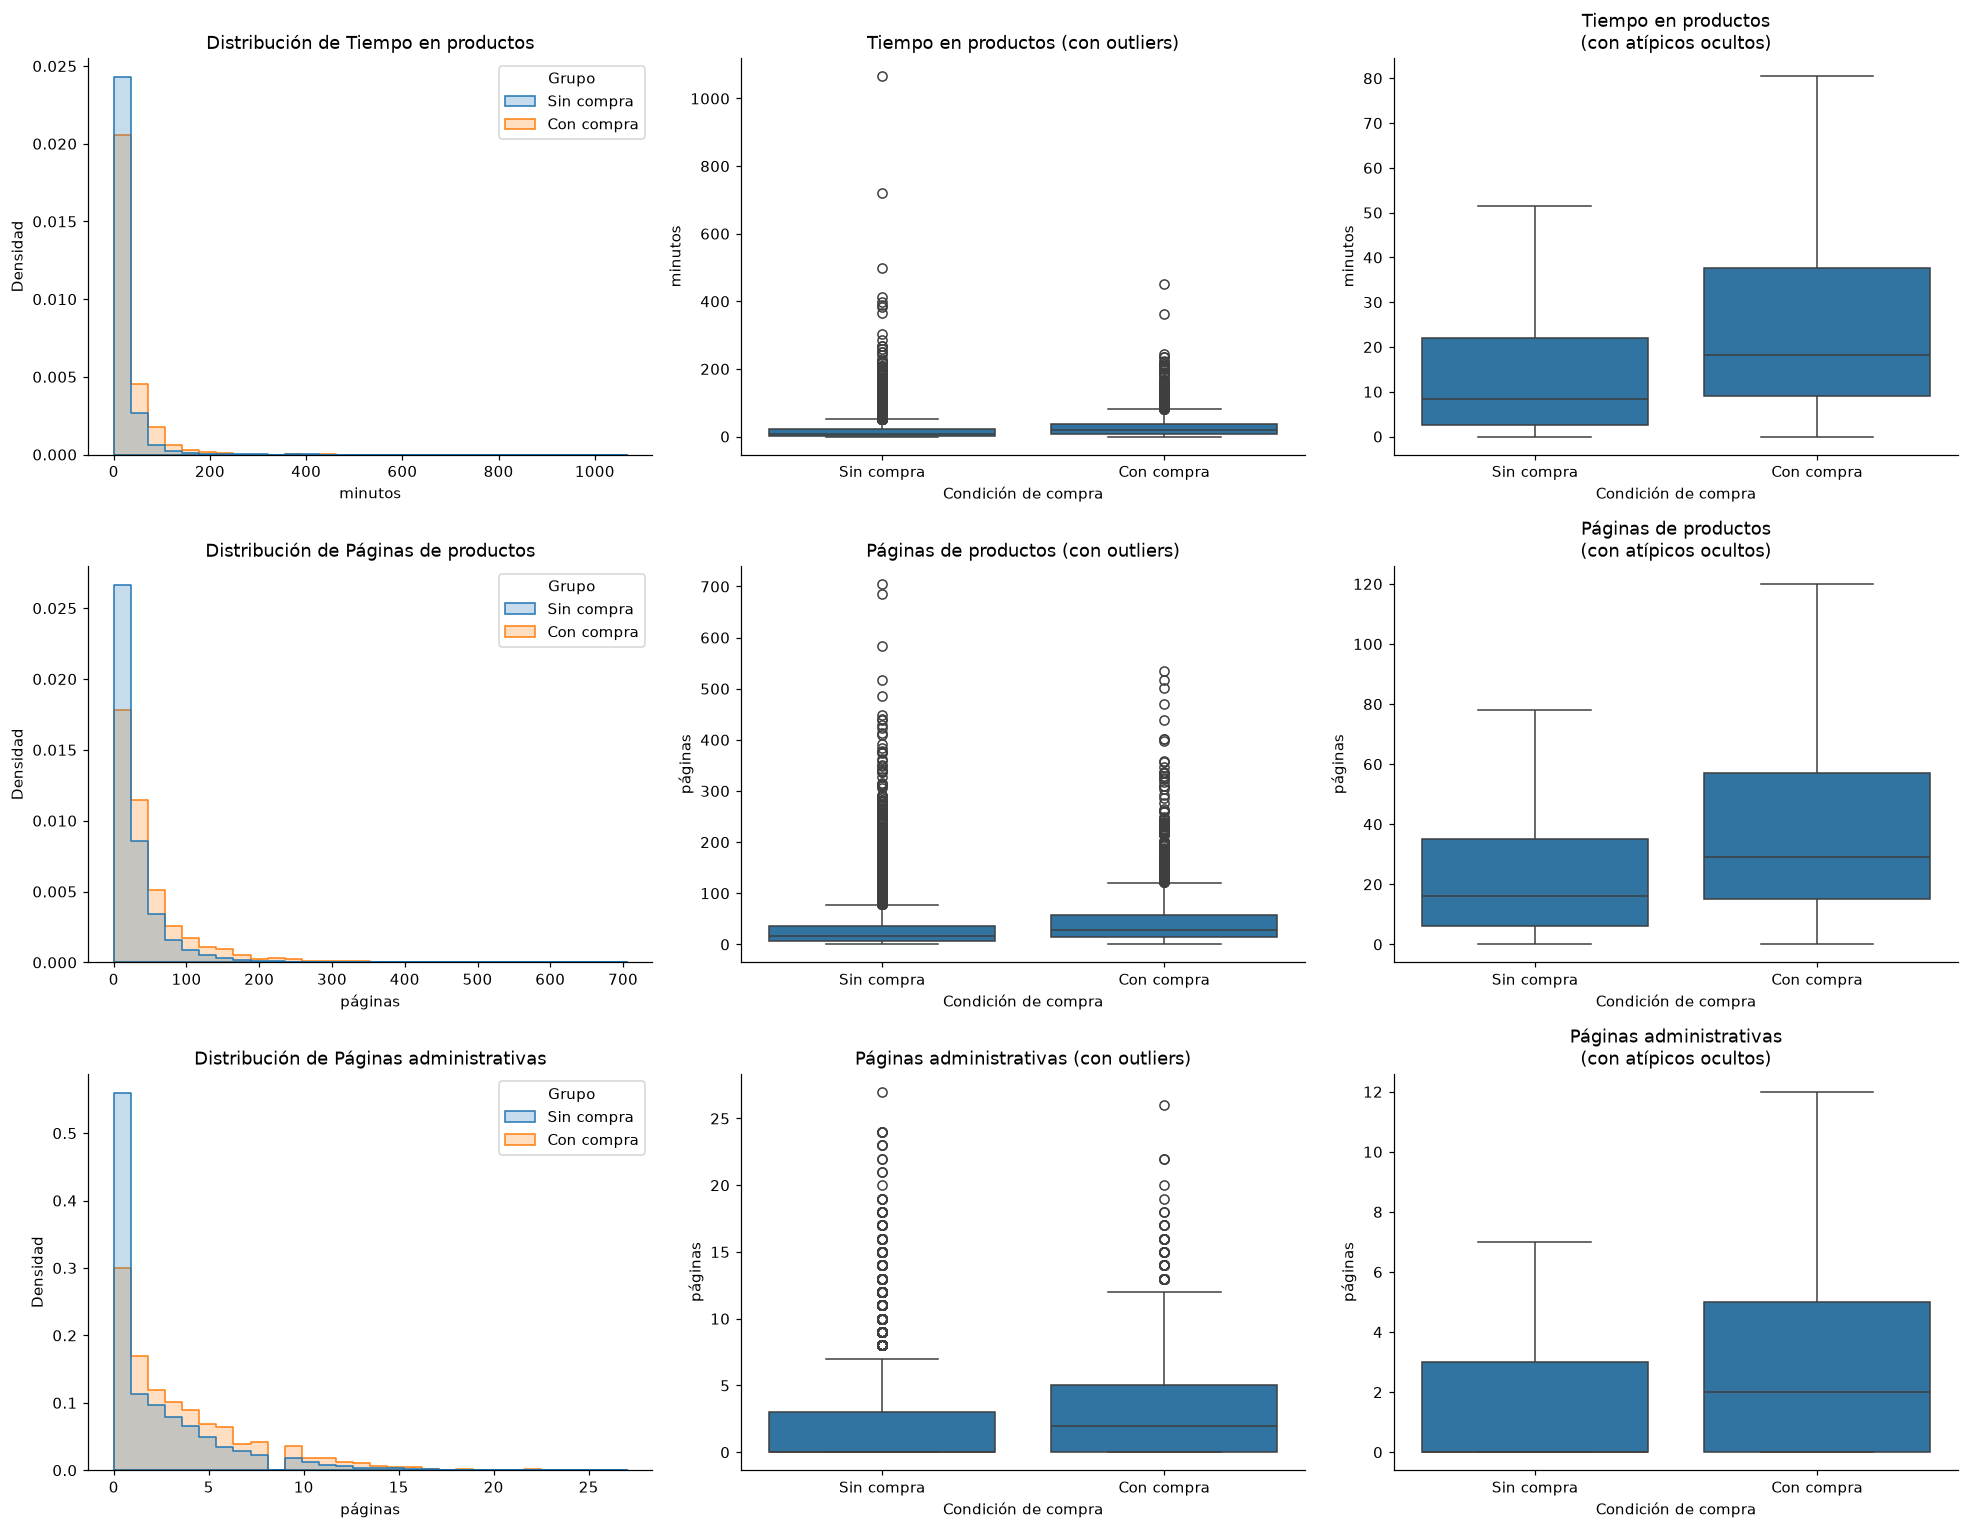

In [11]:
import matplotlib.pyplot as plt

# Figura con 3 filas y 3 columnas
fig, ejes = plt.subplots(3, 3, figsize=(18, 14))

for i, variable in enumerate(seleccionadas):

    # -------------------------
    # Columna 1: Histograma
    # -------------------------
    sns.histplot(
        data=df,
        x=variable,
        hue="Grupo",
        hue_order=grupos,
        stat="density",
        common_norm=False,
        bins=30,
        element="step",
        ax=ejes[i, 0]
    )
    ejes[i, 0].set_title(f"Distribución de {nombres[variable]}")
    ejes[i, 0].set_xlabel(unidades[variable])
    ejes[i, 0].set_ylabel("Densidad")

    # -------------------------
    # Columna 2: Boxplot con outliers
    # -------------------------
    sns.boxplot(
        data=df,
        x="Grupo",
        y=variable,
        order=grupos,
        showfliers=True,
        ax=ejes[i, 1]
    )
    ejes[i, 1].set_title(f"{nombres[variable]} (con outliers)")
    ejes[i, 1].set_xlabel("Condición de compra")
    ejes[i, 1].set_ylabel(unidades[variable])

    # -------------------------
    # Columna 3: Boxplot con atípicos ocultos
    # -------------------------
    sns.boxplot(
        data=df,
        x="Grupo",
        y=variable,
        order=grupos,
        showfliers=False,
        ax=ejes[i, 2]
    )
    ejes[i, 2].set_title(f"{nombres[variable]}\n(con atípicos ocultos)")
    ejes[i, 2].set_xlabel("Condición de compra")
    ejes[i, 2].set_ylabel(unidades[variable])

plt.tight_layout()
plt.show()

**Interpretación de los gráficos**
Los histogramas muestran que las tres variables presentan distribuciones asimétricas hacia la derecha, con una mayor concentración de observaciones en valores bajos y algunos valores elevados menos frecuentes.
Los diagramas de caja con outliers permiten observar la presencia de valores extremos en ambos grupos, mientras que los diagramas con atípicos ocultos facilitan la comparación de las medianas y de la dispersión central.
En general, las sesiones con compra presentan valores centrales (medianas y los cuartiles) mayores que las sesiones sin compra, especialmente en el tiempo dedicado a páginas de productos y en la cantidad de páginas de productos visitadas. 

### 5.6. Análisis bivariado y correlaciones

Se analizaron las relaciones entre las tres variables numéricas seleccionadas mediante gráficos de dispersión y el **coeficiente de correlación de Pearson**.[8]. 
Los gráficos permiten observar cómo se relacionan dos variables, diferenciando las sesiones con compra y sin compra. Por su parte, el coeficiente de Pearson permite medir la fuerza y dirección de la relación lineal entre ellas.
Para realizar este análisis se utilizaron las sesiones que cuentan con información en las tres variables. Se debe considerar que los valores extremos pueden influir en las correlaciones y que una relación entre variables no implica necesariamente causalidad.

Matriz de correlaciones:


,Tiempo_minutos,ProductRelated,Administrative
Tiempo_minutos,1.000,0.858,0.372
ProductRelated,0.858,1.000,0.429
Administrative,0.372,0.429,1.000


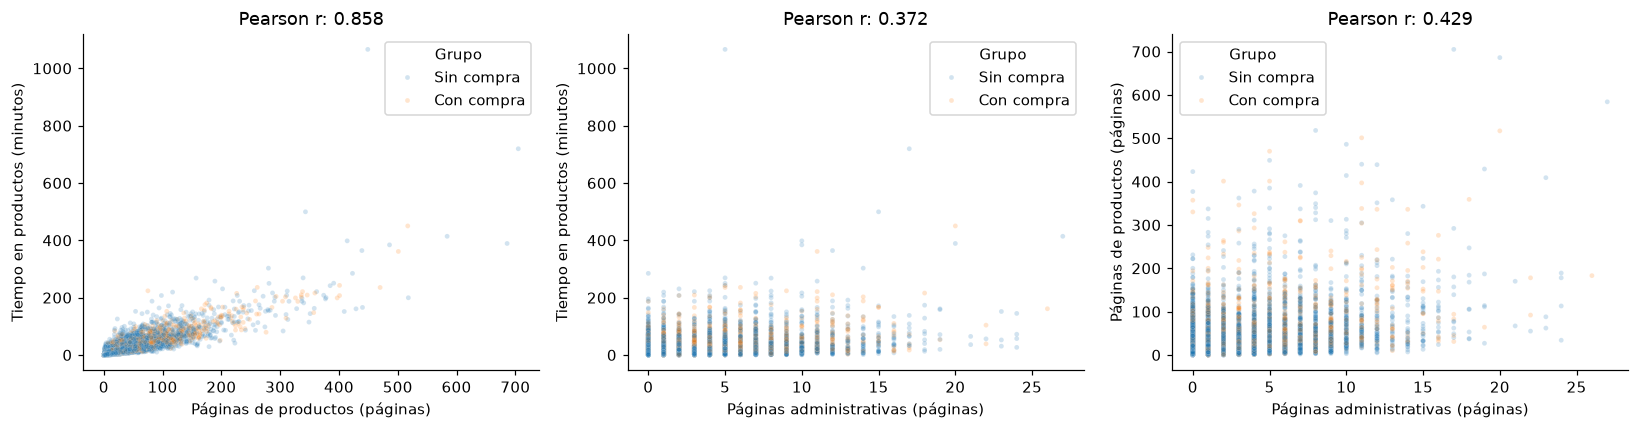

In [12]:
# Seleccionar casos con datos disponibles
df_bivariado = df.dropna(subset=seleccionadas)

# Calcular correlaciones de Pearson
correlaciones = df_bivariado[seleccionadas].corr()

print("Matriz de correlaciones:")
display(correlaciones.round(3))

# Parejas de variables para comparar
pares = [
    ("ProductRelated", "Tiempo_minutos"),
    ("Administrative", "Tiempo_minutos"),
    ("Administrative", "ProductRelated")
]

# Crear tres gráficos de dispersión
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for i, (x, y) in enumerate(pares):
    sns.scatterplot(
        data=df_bivariado,
        x=x,
        y=y,
        hue="Grupo",
        hue_order=grupos,
        alpha=0.2,
        s=10,
        ax=ejes[i]
    )

    r = correlaciones.loc[x, y]

    ejes[i].set_title(f"Pearson r: {r:.3f}")
    ejes[i].set_xlabel(f"{nombres[x]} ({unidades[x]})")
    ejes[i].set_ylabel(f"{nombres[y]} ({unidades[y]})")

plt.tight_layout()
plt.show()

**Interpretación.** 
Los resultados muestran relaciones positivas entre las tres variables analizadas, es decir, cuando una aumenta, la otra también tiende a aumentar.
La correlación más alta se observa entre la cantidad de páginas de productos visitadas y el tiempo dedicado a ellas (**r = 0,858**), lo que indica una relación lineal fuerte.
Por otra parte, las páginas administrativas presentan correlaciones positivas, pero más moderadas, tanto con las páginas de productos (**r = 0,429**) como con el tiempo de navegación en productos (**r = 0,372**).
En conclusión, las variables de navegación están relacionadas, especialmente el tiempo y la cantidad de páginas de productos visitadas. Sin embargo, estas correlaciones no permiten afirmar que una variable sea la causa de los cambios en otra.

## 6. Revisión de condiciones para el análisis estadístico

Antes de calcular los intervalos de confianza y realizar las pruebas de hipótesis, se revisaron las principales condiciones que permiten aplicar estos procedimientos.
| Condición | Evaluación |
|---|---|
| Independencia | Se considera que las sesiones son independientes, aunque no es posible comprobarlo completamente con los datos disponibles. |
| Tamaño de las muestras | Ambos grupos cuentan con más de 1.700 observaciones, lo que favorece la aplicación de métodos estadísticos basados en las medias. |
| Distribución de los datos | Los histogramas y diagramas de caja muestran distribuciones asimétricas y presencia de valores atípicos. |
| Varianzas | No se conocen las varianzas poblacionales y no se asume que sean iguales entre los grupos. |

Considerando estas características, se utilizarán intervalos de confianza basados en la distribución t de Student y pruebas t de Welch para comparar las medias de las sesiones con compra y sin compra.

La prueba de Welch permite realizar comparaciones sin exigir que ambos grupos tengan la misma varianza.

**Evaluación de las condiciones**

Los resultados del análisis exploratorio muestran que las variables presentan distribuciones asimétricas y valores extremos. Bajo el supuesto de independencia y varianzas finitas, el **Teorema del Límite Central** permite aproximar la distribución muestral de la media por una distribución normal cuando el tamaño de muestra es suficientemente grande [9]. Esta aproximación se refiere a las medias que se obtendrían en muestras repetidas; no implica que los datos originales se vuelvan normales, pues mantienen su asimetría. Los tamaños elevados respaldan el uso aproximado de los procedimientos basados en medias, sin eliminar la influencia de los valores extremos.
Para las comparaciones entre sesiones con compra y sin compra se utilizará la prueba t de Welch, que no requiere asumir varianzas iguales.
Los resultados deberán interpretarse con cautela, ya que la independencia de las sesiones no puede verificarse completamente y los valores extremos pueden influir en las estimaciones. Además, las conclusiones se limitarán al conjunto de datos analizado, sin generalizarlas a todo el comercio electrónico.

## 7. Estimación puntual e intervalos de confianza del 95%

Para cada variable y grupo, la media muestral $\bar{x}$ estima la media de las sesiones comparables. Con desviación poblacional desconocida, el intervalo se construye mediante [10, 11]:

$$IC_{95\%}(\mu)=\bar{x}\pm t_{0{,}975;n-1}\frac{s}{\sqrt{n}}.$$

El **error estándar** $s/\sqrt{n}$ expresa la incertidumbre de la media y se distingue de $s$, que describe la variabilidad de las sesiones. `stats.t.interval` calcula los límites usando el tamaño efectivo de cada grupo; no se redondean resultados intermedios. Se obtienen seis intervalos, correspondientes a **tres variables distintas en dos grupos**.

El nivel de confianza describe la cobertura del procedimiento en muestreos repetidos bajo sus supuestos. No significa que el 95% de las sesiones esté entre los límites ni que la media poblacional sea aleatoria. Los intervalos son individuales: su conjunto no constituye una región de confianza simultánea del 95%.

In [13]:
registros_intervalos = []
for variable in seleccionadas:
    for grupo in grupos:
        valores = df.loc[df["Grupo"] == grupo, variable].dropna()
        n = len(valores)
        media = valores.mean()
        desviacion = valores.std(ddof=1)
        error_estandar = desviacion / np.sqrt(n)
        inferior, superior = stats.t.interval(confidence=confianza, df=n - 1,
                                               loc=media, scale=error_estandar)
        registros_intervalos.append({"Variable": nombres[variable], "Grupo": grupo,
            "Unidad": unidades[variable], "n": n, "Media": media,
            "Desv. estándar": desviacion, "Error estándar": error_estandar,
            "Grados de libertad": n - 1, "IC 95% inferior": inferior,
            "IC 95% superior": superior, "Margen de error": superior - media})
intervalos = pd.DataFrame(registros_intervalos).set_index(["Variable", "Grupo"])
display(intervalos.round(3))

Unidad      n   Media  Desv. estándar  \
Variable                Grupo                                                
Tiempo en productos     Sin compra  minutos   9387  17.858          30.522   
                        Con compra  minutos   1710  30.991          37.654   
Páginas de productos    Sin compra  páginas  10422  28.715          40.745   
                        Con compra  páginas   1908  48.210          58.267   
Páginas administrativas Sin compra  páginas  10422   2.118           3.202   
                        Con compra  páginas   1908   3.394           3.731   

                                    Error estándar  Grados de libertad  \
Variable                Grupo                                            
Tiempo en productos     Sin compra           0.315                9386   
                        Con compra           0.911                1709   
Páginas de productos    Sin compra           0.399               10421   
                        Con compra           1.334                1907   
Páginas administrativas Sin compra           0.031               10421   
                        Con compra           0.085                1907   

                                    IC 95% inferior  IC 95% superior  \
Variable                Grupo                                          
Tiempo en productos     Sin compra           17.241           18.476   
                        Con compra           29.205           32.777   
Páginas de productos    Sin compra           27.932           29.497   
                        Con compra           45.594           50.826   
Páginas administrativas Sin compra            2.056            2.179   
                        Con compra            3.226            3.561   

                                    Margen de error  
Variable                Grupo                        
Tiempo en productos     Sin compra            0.618  
                        Con compra            1.786  
Páginas de productos    Sin compra            0.782  
                        Con compra            2.616  
Páginas administrativas Sin compra            0.061  
                        Con compra            0.167

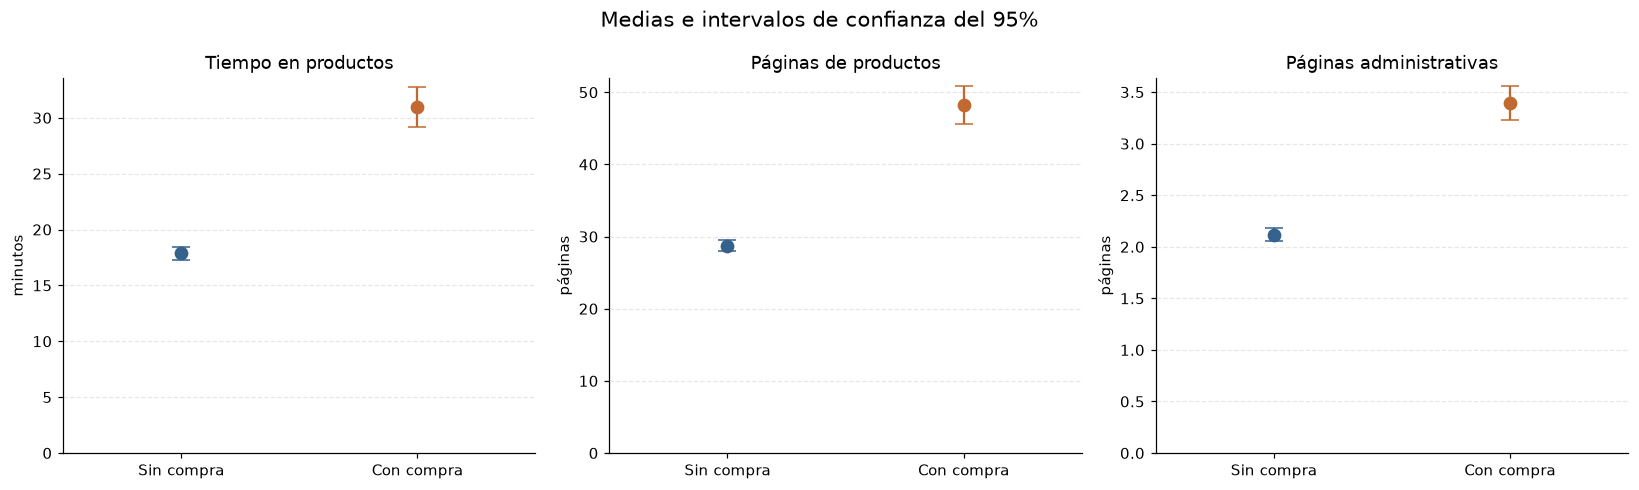

In [14]:
# Crear los tres gráficos de intervalos de confianza
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for eje, variable in zip(ejes, seleccionadas):
    tabla = intervalos.loc[nombres[variable]].reindex(grupos)
    for posicion, grupo in enumerate(grupos):
        fila = tabla.loc[grupo]
        eje.errorbar(
            posicion,
            fila["Media"],
            yerr=fila["Margen de error"],
            fmt="o",
            capsize=6,
            markersize=8,
            color=colores[grupo]
        )

    eje.set_xticks([0, 1])
    eje.set_xticklabels(grupos)
    eje.set_title(nombres[variable])
    eje.set_ylabel(unidades[variable])
    eje.set_xlim(-0.5, 1.5)
    eje.set_ylim(bottom=0)
    eje.grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle(
    "Medias e intervalos de confianza del 95%",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Tiempo en productos.** La media estimada sin compra es 17,86 minutos (IC 95%: **17,24 a 18,48**); con compra es 30,99 (IC 95%: **29,21 a 32,78**).

**Páginas de productos.** La media estimada sin compra es 28,71 páginas (IC 95%: **27,93 a 29,50**); con compra es 48,21 (IC 95%: **45,59 a 50,83**).

**Páginas administrativas.** La media estimada sin compra es 2,12 páginas (IC 95%: **2,06 a 2,18**); con compra es 3,39 (IC 95%: **3,23 a 3,56**).

Los intervalos cuantifican incertidumbre sobre las medias. Las medias estimadas son mayores en el grupo con compra para las tres variables. Los intervalos más amplios del grupo con compra reflejan su menor tamaño y su variabilidad. Los intervalos de páginas administrativas se interpretan como estimación y no se sustituyen por una decisión de un tercer contraste. Para las otras dos variables, la comparación formal se realiza a continuación mediante la diferencia de medias.

## 8. Pruebas de hipótesis para dos muestras independientes

Se fijan **dos comparaciones** relacionadas con la pregunta de investigación. En ambas, la diferencia se define como **media con compra menos media sin compra**. La alternativa es bilateral, porque la pregunta plantea diferencias en cualquiera de las dos direcciones.

| Contraste | Hipótesis nula $H_0$ | Hipótesis alternativa $H_1$ | Parámetro |
|---|---|---|---|
| Tiempo en productos | $\mu_{\mathrm{con}}-\mu_{\mathrm{sin}}=0$ | $\mu_{\mathrm{con}}-\mu_{\mathrm{sin}}\ne0$ | Diferencia de tiempo medio en minutos |
| Páginas de productos | $\mu_{\mathrm{con}}-\mu_{\mathrm{sin}}=0$ | $\mu_{\mathrm{con}}-\mu_{\mathrm{sin}}\ne0$ | Diferencia de cantidad media de páginas |

Se establece **$\alpha=0{,}05$ por contraste**, como tolerancia de error Tipo I: rechazar la igualdad de medias cuando es verdadera, bajo los supuestos del procedimiento [12, 13]. Es un criterio convencional que permite separar la decisión estadística de la magnitud observada. No se interpreta como la probabilidad de que la conclusión sea errónea. Al realizar dos contrastes sin ajuste de multiplicidad, el error del conjunto no queda controlado al 5%; ambos resultados se reportan sin seleccionar únicamente los significativos.

La **prueba t de Welch** utiliza `stats.ttest_ind(..., equal_var=False, alternative="two-sided")`. Se elige porque los grupos son independientes, de tamaños desiguales y no se impone igualdad de varianzas [12]. El estadístico divide la diferencia de medias por su error estándar:

$$t=\frac{\bar{x}_{\mathrm{con}}-\bar{x}_{\mathrm{sin}}}{\sqrt{s^2_{\mathrm{con}}/n_{\mathrm{con}}+s^2_{\mathrm{sin}}/n_{\mathrm{sin}}}}.$$

Los grados de libertad se calculan con la aproximación de Welch-Satterthwaite. Se reportan el valor p, el intervalo del 95% de la diferencia y el **tamaño del efecto d de Cohen**, definido como la diferencia dividida por la desviación estándar combinada [11, 12]. Esta estandarización no implica usar varianzas iguales en la prueba. Dadas las distribuciones asimétricas, la interpretación práctica se centra también en minutos o páginas y en la superposición entre grupos.

In [15]:
def comparar_medias(variable):
    con = df.loc[df["Grupo"] == "Con compra", variable].dropna()
    sin = df.loc[df["Grupo"] == "Sin compra", variable].dropna()
    n_con, n_sin = len(con), len(sin)
    var_con, var_sin = con.var(ddof=1), sin.var(ddof=1)
    diferencia = con.mean() - sin.mean()
    error = np.sqrt(var_con / n_con + var_sin / n_sin)
    grados = (var_con / n_con + var_sin / n_sin) ** 2 / (
        (var_con / n_con) ** 2 / (n_con - 1) +
        (var_sin / n_sin) ** 2 / (n_sin - 1)
    )
    resultado = stats.ttest_ind(con, sin, equal_var=False, alternative="two-sided")
    critico = stats.t.ppf(1 - (1 - confianza) / 2, df=grados)
    inferior, superior = diferencia - critico * error, diferencia + critico * error
    desviacion_combinada = np.sqrt(
        ((n_con - 1) * var_con + (n_sin - 1) * var_sin) / (n_con + n_sin - 2)
    )
    return {"Variable": nombres[variable], "Unidad": unidades[variable],
            "n sin compra": n_sin, "n con compra": n_con,
            "Media sin compra": sin.mean(), "Media con compra": con.mean(),
            "Diferencia": diferencia, "Error estándar diferencia": error,
            "t": resultado.statistic, "Grados de libertad": grados,
            "Valor p": resultado.pvalue, "IC 95% inferior": inferior,
            "IC 95% superior": superior, "d de Cohen": diferencia / desviacion_combinada,
            "Decisión": "Rechazar H0" if resultado.pvalue < alfa else "No rechazar H0"}

contrastes = pd.DataFrame([
    comparar_medias("Tiempo_minutos"), comparar_medias("ProductRelated")
]).set_index("Variable")
display(contrastes[["Unidad", "n sin compra", "n con compra", "Media sin compra",
                    "Media con compra", "Diferencia", "Error estándar diferencia"]].round(3))
display(contrastes[["t", "Grados de libertad", "Valor p", "IC 95% inferior",
                    "IC 95% superior", "d de Cohen", "Decisión"]].style.format({
    "t": "{:.4f}", "Grados de libertad": "{:.2f}", "Valor p": "{:.3e}",
    "IC 95% inferior": "{:.3f}", "IC 95% superior": "{:.3f}", "d de Cohen": "{:.3f}"}))

,Unidad,n sin compra,n con compra,Media sin compra,Media con compra,Diferencia,Error estándar diferencia
Variable,,,,,,,
Tiempo en productos,minutos,9387,1710,17.858,30.991,13.133,0.964
Páginas de productos,páginas,10422,1908,28.715,48.210,19.496,1.392


,t,Grados de libertad,Valor p,IC 95% inferior,IC 95% superior,d de Cohen,Decisión
Variable,,,,,,,
Tiempo en productos,13.6302,2137.04,1.257e-40,11.243,15.022,0.414,Rechazar H0
Páginas de productos,14.0017,2260.40,8.835e-43,16.765,22.226,0.444,Rechazar H0


### 8.1. Resultado del contraste de tiempo en productos

La decisión se basa en el valor p respecto de $\alpha$. El intervalo de la diferencia se calcula con su propio error estándar; no se obtiene restando los extremos de los dos intervalos individuales. El valor p describe la probabilidad, bajo $H_0$ y los supuestos, de un estadístico tan extremo o más que el observado; no es la probabilidad de que $H_0$ sea verdadera.

El tiempo medio es **30,99 minutos con compra** y **17,86 sin compra**. La diferencia estimada es **13,13 minutos**, con IC 95% de **11,24 a 15,02**. La prueba obtiene t = 13,6302, 2.137,04 grados de libertad y p = 1.257e-40. La decisión es **Rechazar H0**, con α = 0,05. El tamaño del efecto es d = **0,414**. Existe evidencia de una diferencia de medias y el signo observado indica mayor tiempo en las sesiones con compra. La diferencia puede orientar una revisión de los recorridos de productos, pero no demuestra que prolongar una sesión aumente su probabilidad de compra.

### 8.2. Resultado del contraste de páginas de productos

Se utiliza el mismo criterio bilateral para comparar cantidades medias de páginas. Se mantienen todas las sesiones porque esta variable no tiene faltantes. La interpretación se expresa en páginas por sesión y considera tanto la evidencia estadística como la magnitud de la diferencia.

La cantidad media es **48,21 páginas con compra** y **28,71 sin compra**. La diferencia estimada es **19,50 páginas**, con IC 95% de **16,77 a 22,23**. La prueba obtiene t = 14,0017, 2.260,40 grados de libertad y p = 8.835e-43. La decisión es **Rechazar H0**, con α = 0,05. El tamaño del efecto es d = **0,444**. Existe evidencia de una diferencia de medias, con mayor cantidad de páginas de productos en las sesiones con compra. Esto justifica estudiar cómo se exploran y comparan productos, sin convertir un conteo alto en una condición suficiente ni en una causa de compra.

**Alcance práctico de los contrastes.** Los valores p muy pequeños no equivalen a cero ni cuantifican la importancia comercial. Los valores d expresan diferencias menores que una desviación estándar combinada, coherentes con la superposición observada. Sin información sobre objetivos comerciales, costos o valor de las transacciones, no se establece un umbral de mejora relevante para la tienda. Las dos comparaciones son marginales: no ajustan simultáneamente por cantidad de páginas, tiempo, mes o tipo de visitante.

## 9. Resultados principales y conclusiones

En esta sección se resumen los principales resultados del análisis estadístico, comparando el comportamiento de navegación entre las sesiones con compra y sin compra.
La siguiente tabla presenta las medias y sus intervalos de confianza del 95% para las tres variables analizadas. También se indican los resultados de las pruebas de hipótesis realizadas sobre el tiempo de navegación y la cantidad de páginas de productos visitadas.

In [16]:
sintesis = []
for variable in seleccionadas:
    nombre = nombres[variable]
    sin = intervalos.loc[(nombre, "Sin compra")]
    con = intervalos.loc[(nombre, "Con compra")]
    decision = contrastes.loc[nombre, "Decisión"] if nombre in contrastes.index else "Estimación sin contraste"
    sintesis.append({"Variable": nombre, "Unidad": unidades[variable],
        "Sin compra: media [IC 95%]": f"{numero(sin['Media'])} [{numero(sin['IC 95% inferior'])}; {numero(sin['IC 95% superior'])}]",
        "Con compra: media [IC 95%]": f"{numero(con['Media'])} [{numero(con['IC 95% inferior'])}; {numero(con['IC 95% superior'])}]",
        "Alcance": decision})
display(pd.DataFrame(sintesis).set_index("Variable"))

,Unidad,Sin compra: media [IC 95%],Con compra: media [IC 95%],Alcance
Variable,,,,
Tiempo en productos,minutos,"17,86 [17,24; 18,48]","30,99 [29,21; 32,78]",Rechazar H0
Páginas de productos,páginas,"28,71 [27,93; 29,50]","48,21 [45,59; 50,83]",Rechazar H0
Páginas administrativas,páginas,"2,12 [2,06; 2,18]","3,39 [3,23; 3,56]",Estimación sin contraste


### 9.1. Conclusiones del análisis

Los resultados muestran que las sesiones con compra presentan, en promedio, mayor tiempo de navegación y mayor cantidad de páginas visitadas que las sesiones sin compra.
Esta diferencia se observa especialmente en las páginas de productos, donde las sesiones con compra registran un promedio de **30,99 minutos**, frente a **17,86 minutos** en las sesiones sin compra. Asimismo, visitan un promedio de **48,21 páginas de productos**, en comparación con **28,71 páginas** de las sesiones sin compra.
Las pruebas de hipótesis realizadas confirman que existen diferencias estadísticamente significativas entre ambos grupos para estas dos variables.
Por otra parte, el análisis de correlación muestra una relación positiva fuerte entre la cantidad de páginas de productos y el tiempo dedicado a ellas, lo que indica que ambas características de navegación están relacionadas.
En conclusión, el comportamiento de navegación presenta diferencias según la condición de compra. Sin embargo, estos resultados muestran asociaciones y no permiten afirmar que visitar más páginas o permanecer más tiempo en ellas provoque una compra.

### 9.2. Limitaciones del análisis

Aunque los resultados permiten identificar diferencias entre los grupos, es importante considerar algunas limitaciones:
- **Datos disponibles:** el análisis corresponde a sesiones de navegación de un sitio y período específicos, por lo que los resultados no necesariamente representan a todo el comercio electrónico.
- **Características de los datos:** existen valores extremos y distribuciones asimétricas que pueden influir en los promedios. Además, algunas observaciones presentan valores faltantes incorporados para el ejercicio.
- **Alcance del análisis:** se compararon las variables de manera individual, sin considerar simultáneamente otros factores, como el mes, el tipo de visitante o el origen del tráfico.
Estas limitaciones deben considerarse al interpretar los resultados y al evaluar posibles aplicaciones comerciales.

### 9.3. Próximos pasos

Como continuación del proyecto, se propone profundizar el análisis considerando otras características de las sesiones, como el mes y el tipo de visitante, para identificar si los patrones observados se mantienen en diferentes grupos.
También sería útil estudiar el efecto de los valores extremos y evaluar alternativas para tratar los datos faltantes.
Finalmente, para utilizar estos resultados en decisiones comerciales, sería necesario incorporar información adicional que permita comprender mejor el comportamiento de los usuarios y evaluar la importancia práctica de las diferencias encontradas.

## 10. Referencias y trazabilidad metodológica

1. Sakar, C. y Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [DOI: 10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q). Fuente, estructura, unidad de observación y condición de compra.
2. Köktürk Güzel, B. E. y Ünay, D. (2021). *Predicting Purchase Interest of Online Shoppers Using Boosting Algorithms*. Natural & Applied Sciences Journal, 4(2), 32–37. [Texto completo, tabla 1, p. 35](https://dergipark.org.tr/en/download/article-file/1472801). Definición de páginas administrativas y unidades de duración.
3. Maidana, J. P. (2026). *Bases de datos disponibles para el proyecto del curso*. Universidad Andrés Bello. `f2_s01_apuntes_Dataset.pdf`, p. 3. Mecanismo MCAR, semilla fija y conservación de originales.
4. Maidana, J. P. (2026). *Tipos de variables y exploración de datos con pandas*. Universidad Andrés Bello. `f1_s01_apunte_tipos de variables.pdf`. Clasificación, exploración, tipos y memoria.
5. Universidad Andrés Bello. *Medidas de tendencia central*. `f2_s01_apunte_Tendencia.pdf`. Media, mediana, moda y cuartiles.
6. Universidad Andrés Bello. *Medidas de dispersión y forma*. `f2_s01_apunte_Dispersión.pdf`. Varianza, desviación estándar, CV, RIC, asimetría, curtosis y atípicos.
7. Universidad Andrés Bello. *Visualización de datos con Seaborn*. `f1_s01_apunte_visualización.pdf`. Selección de histogramas, diagramas de cajas y barras; las figuras se implementan con Matplotlib y Seaborn.
8. Universidad Andrés Bello. *Workflow completo de análisis estadístico*. `f2_s01_tutorial_workflow.ipynb`. Secuencia de calidad, descriptiva, visualización, correlaciones, supuestos e inferencia.
9. Universidad Andrés Bello. *Inferencia estadística: de la muestra a la población*. `f2_s01_apunte_Inferencia.pdf`. Distribución muestral, error estándar, Teorema del Límite Central y límites de generalización.
10. Universidad Andrés Bello. *Intervalos de confianza: cuantificando la incertidumbre estadística*. `f2_s01_apunte_Media.pdf`. Intervalo t para una media con desviación poblacional desconocida.
11. Universidad Andrés Bello. *Intervalos de confianza en diferentes escenarios*. `f2_s01_tutorial_python.ipynb`, escenarios 1.2 y 3. Intervalos para medias y diferencias de medias independientes.
12. Universidad Andrés Bello. *Tutorial exhaustivo: pruebas de hipótesis*. `f2_s01_tutorial_suite.ipynb`, escenarios 3 y 5 y guía de reporte. Welch, grados de libertad, d de Cohen y evaluación gráfica con Q-Q.
13. Universidad Andrés Bello. *Pruebas de hipótesis: pruebas t y Z para una muestra*. `f2_s01_apunte_PruebaT.pdf`. Hipótesis, significancia, valor p y errores Tipo I y II.

Las fuentes metodológicas se identifican por sus títulos y archivos. El análisis utiliza exclusivamente las entradas locales descritas en la sección 2; no requiere descargar datos ni consultar servicios externos durante su ejecución.